# Практическая работа № 2. Разведочный анализ данных (EDA)

**Уровень:** B (данные заданы)
**Цель:** пройти последовательность разведочного анализа: типы признаков, распределения, пропуски, выбросы, связи между признаками — и составить список проблем данных, которые устраним в ПР-3.

**Данные:** `data/housing.csv` (тот же датасет, что в ПР-1). Задача — предсказание цены квартиры (регрессия).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
from preprocessing import clean_raw     # правила очистки, нужны для сравнения «до/после»

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/housing.csv")
print("Размер:", df.shape)

Размер: (1010, 11)


## 1. Общий осмотр и классификация признаков

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_m2         980 non-null    float64
 1   living_area_m2  1010 non-null   float64
 2   area_sqft       1010 non-null   float64
 3   rooms           1010 non-null   int64  
 4   floor           980 non-null    float64
 5   year_built      930 non-null    float64
 6   dist_center_km  960 non-null    float64
 7   district        950 non-null    str    
 8   condition       909 non-null    str    
 9   balcony         1010 non-null   str    
 10  price_kusd      1010 non-null   float64
dtypes: float64(7), int64(1), str(3)
memory usage: 86.9 KB


In [3]:
feature_types = pd.DataFrame({
    "признак": ["area_m2", "living_area_m2", "area_sqft", "dist_center_km", "rooms", "floor",
                "year_built", "district", "condition", "balcony", "price_kusd"],
    "тип": ["числовой непрерывный"] * 4 + ["числовой дискретный"] * 3 +
           ["категориальный номинальный", "категориальный порядковый",
            "категориальный бинарный", "целевая (числовая непрерывная)"],
    "комментарий": ["площадь, м²", "жилая площадь, м²", "площадь в квадратных футах",
                    "расстояние до центра, км", "число комнат", "этаж", "год постройки (по смыслу — дата, не количество)",
                    "район города", "состояние: требует ремонта < хороший < новый", "есть ли балкон",
                    "цена, тыс. $ — то, что предсказываем"]})
feature_types

           признак                             тип                                      комментарий
0          area_m2            числовой непрерывный                                      площадь, м²
1   living_area_m2            числовой непрерывный                                жилая площадь, м²
2        area_sqft            числовой непрерывный                       площадь в квадратных футах
3   dist_center_km            числовой непрерывный                         расстояние до центра, км
4            rooms             числовой дискретный                                     число комнат
5            floor             числовой дискретный                                             этаж
6       year_built             числовой дискретный  год постройки (по смыслу — дата, не количество)
7         district      категориальный номинальный                                     район города
8        condition       категориальный порядковый     состояние: требует ремонта < хороший < новый


## 2. Пропуски

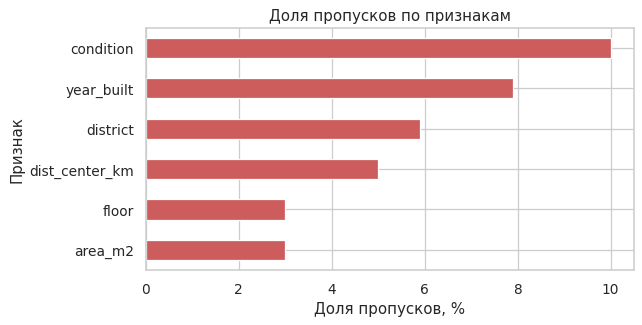

In [4]:
miss = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(7, 3.5))
miss.plot(kind="barh", color="indianred")
plt.title("Доля пропусков по признакам")
plt.xlabel("Доля пропусков, %")
plt.ylabel("Признак")
plt.gca().invert_yaxis()
plt.show()

**Что видно:** пропуски есть в шести признаках; больше всего — в `condition` (≈10%) и `year_built` (8%). В целевой переменной пропусков нет. Пропуски в `district` и `condition` — категориальные, их нельзя заполнять средним; для них нужна отдельная категория «неизвестно».

In [5]:
# Не связана ли пропущенность с ценой? (если да — пропуски информативны)
print("Средняя цена, если condition известно  :", round(df.loc[df.condition.notna(), "price_kusd"].mean(), 1))
print("Средняя цена, если condition пропущено :", round(df.loc[df.condition.isna(), "price_kusd"].mean(), 1))

Средняя цена, если condition известно  : 94.9
Средняя цена, если condition пропущено : 96.4


Средние цены почти совпадают — пропуски в `condition` выглядят случайными и не несут сигнала о цене.
## 3. Числовые признаки: распределения и выбросы

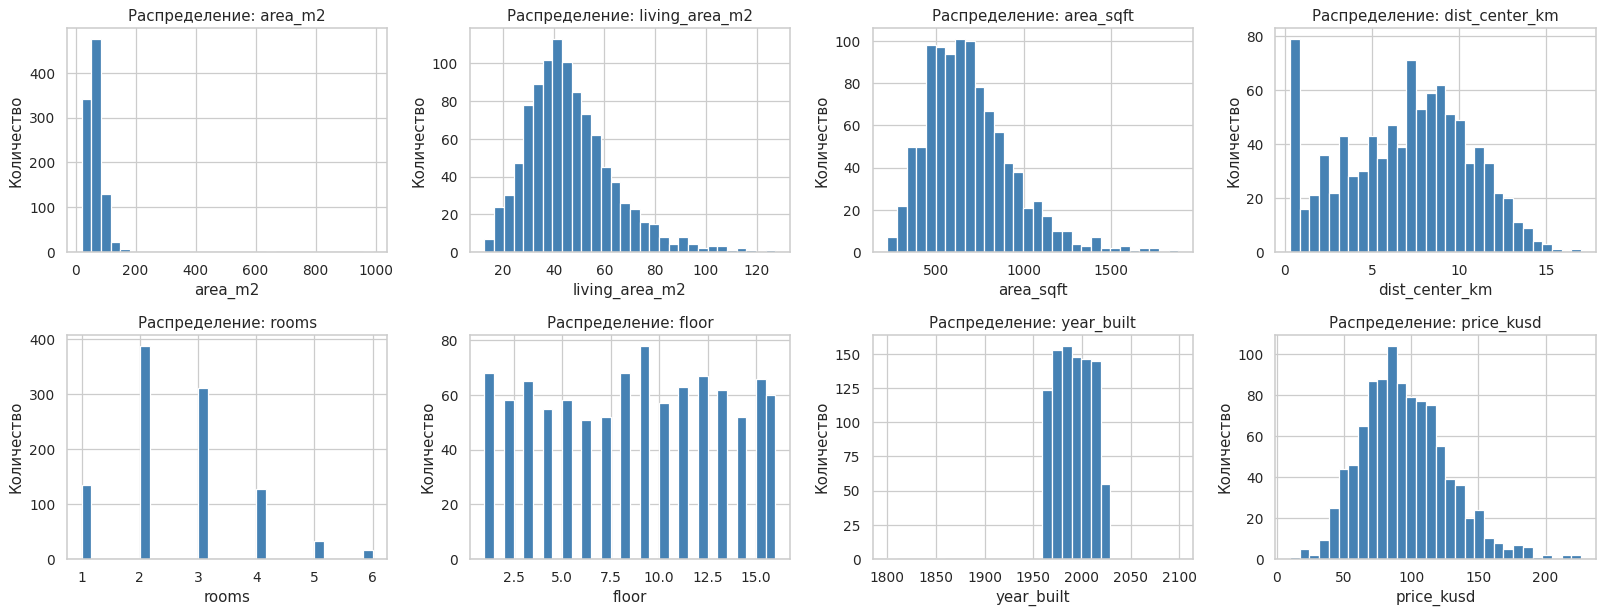

In [6]:
num_cols = ["area_m2", "living_area_m2", "area_sqft", "dist_center_km", "rooms", "floor", "year_built", "price_kusd"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.set_title(f"Распределение: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество")
plt.tight_layout()
plt.show()

**Что видно:** `area_m2`, `area_sqft`, `living_area_m2` скошены вправо; у `area_m2` и `year_built` гистограмма сжата «в один столбик» — признак того, что есть экстремальные значения, искажающие масштаб (то есть выбросы). `floor` и `year_built` распределены примерно равномерно, `price_kusd` — колоколообразно с правым хвостом.

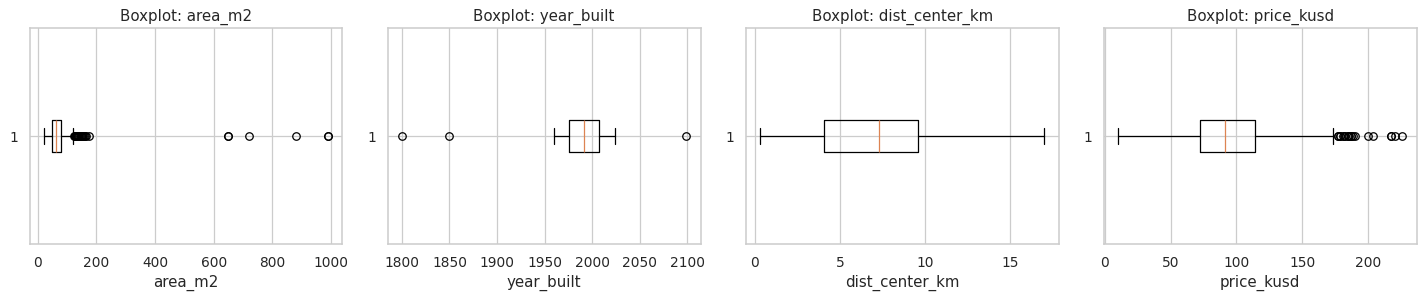

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["area_m2", "year_built", "dist_center_km", "price_kusd"]):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(f"Boxplot: {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

In [8]:
# Критерий выброса: правило Тьюки — значение вне [Q1 − 1.5·IQR; Q3 + 1.5·IQR]
rows = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, round(lo, 1), round(hi, 1), int(((s < lo) | (s > hi)).sum())])
pd.DataFrame(rows, columns=["признак", "нижняя граница", "верхняя граница", "число выбросов по IQR"])

          признак  нижняя граница  верхняя граница  число выбросов по IQR
0         area_m2             3.9            121.7                     29
1  living_area_m2             5.0             85.0                     29
2       area_sqft            50.1           1285.1                     25
3  dist_center_km            -4.2             17.9                      0
4           rooms             0.5              4.5                     48
5           floor            -8.0             24.0                      0
6      year_built          1929.5           2053.5                      3
7      price_kusd             9.3            176.7                     20

**Как решаем, что удалять.** Правило IQR лишь *подозревает* выброс. В `area_m2` оно отмечает 29 значений, но большинство — это реально большие квартиры (100–170 м²), а настоящие ошибки — значения 650–990 м² (квартира в 990 м² в этом датасете невозможна, при том что `living_area_m2` у той же строки обычно 30–80). В `year_built` IQR отмечает ровно 3 значения — это 1800, 1850 и 2099, т. е. невозможные годы. Поэтому критерий очистки — **не статистика, а здравый смысл**: `area_m2 > 400` и год вне 1900–2026 считаем ошибками ввода и заменяем на пропуск (его потом заполнит пайплайн). Выбросы в цене (20 шт. по IQR) — это дорогие квартиры, а не ошибки, поэтому их оставляем.
## 4. Категориальные признаки

district — самая редкая категория: Центр (22%)
condition — самая редкая категория: новый (24%)
balcony — самая редкая категория: нет (38%)


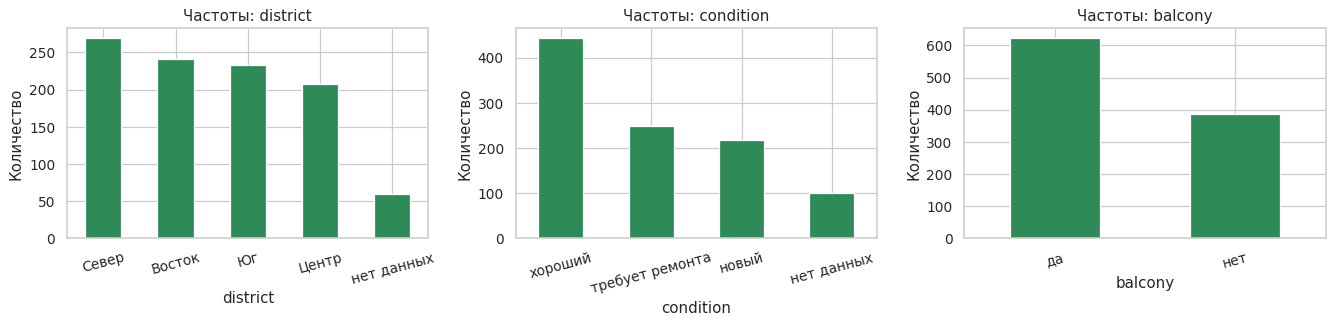

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["district", "condition", "balcony"]):
    vc = df[col].value_counts(dropna=False).rename(index={np.nan: "нет данных"})
    vc.plot(kind="bar", ax=ax, color="seagreen", edgecolor="white")
    ax.set_title(f"Частоты: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

for col in ["district", "condition", "balcony"]:
    share = df[col].value_counts(normalize=True)
    print(col, "— самая редкая категория:", share.idxmin(), f"({share.min():.0%})")

**Что видно:** редких категорий (меньше 5%) нет — все категории представлены достаточно, объединять их не нужно. Самая многочисленная категория в `condition` — «хороший», в `district` — «Север».
## 5. Связи между признаками

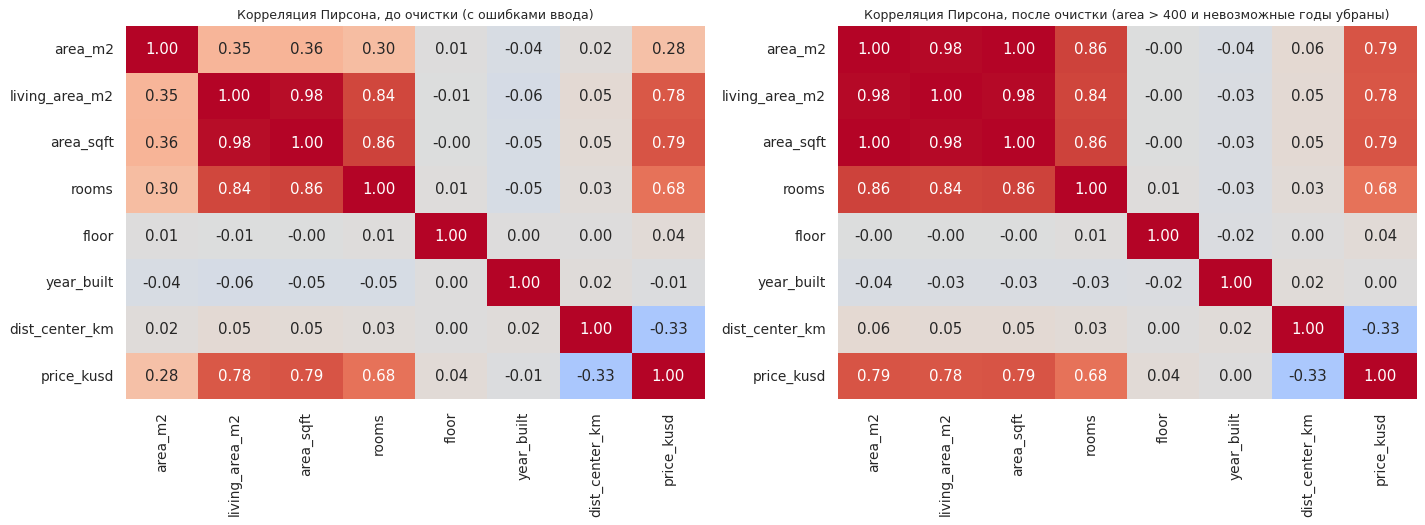

In [10]:
clean = clean_raw(df)
num_for_corr = ["area_m2", "living_area_m2", "area_sqft", "rooms", "floor", "year_built", "dist_center_km", "price_kusd"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, title in zip(axes, [df, clean], ["до очистки (с ошибками ввода)", "после очистки (area > 400 и невозможные годы убраны)"]):
    sns.heatmap(data[num_for_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title("Корреляция Пирсона, " + title, fontsize=10)
plt.tight_layout()
plt.show()

**Что видно:** после очистки корреляция `area_m2` с ценой выросла с ≈0,28 до ≈0,79: несколько опечаток почти скрывали главную зависимость. Кроме того, `area_m2`, `area_sqft` и `living_area_m2` связаны друг с другом (r = 0,98–1,00) — это **мультиколлинеарность**: фактически одна и та же информация в трёх видах. Слабее с ценой связаны `dist_center_km` (r ≈ −0,33: чем дальше от центра, тем дешевле) и `rooms` (≈0,68, но комнаты сами сильно зависят от площади, r ≈ 0,86). `floor` и `year_built` линейно с ценой почти не связаны.

*Оговорка:* корреляция показывает совместное изменение, но не причинность: например, площадь и число комнат растут вместе, и по корреляции нельзя сказать, что именно влияет на цену.

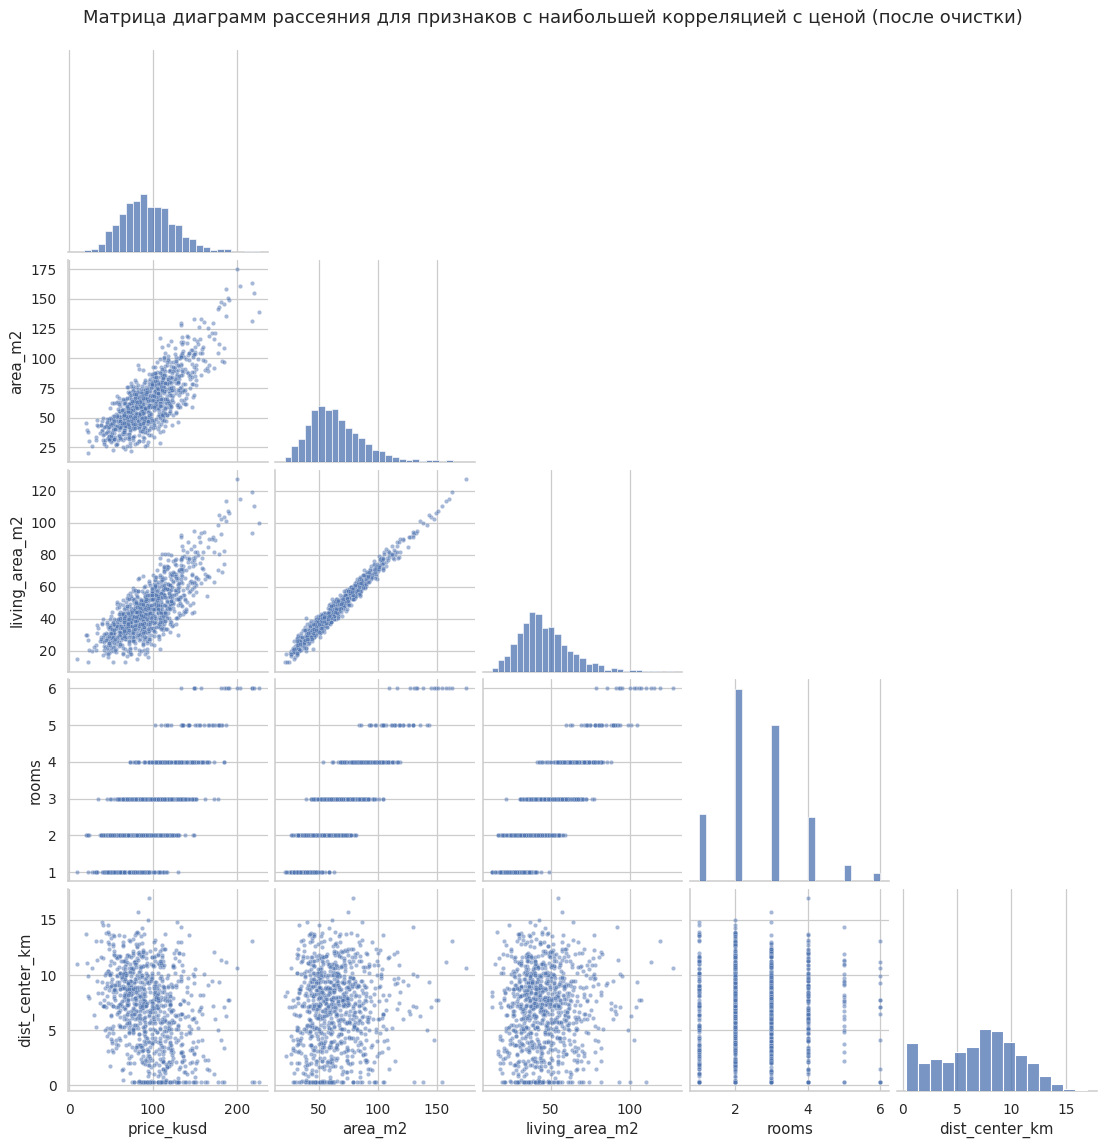

In [11]:
top = ["price_kusd", "area_m2", "living_area_m2", "rooms", "dist_center_km"]
g = sns.pairplot(clean[top], corner=True, plot_kws={"s": 12, "alpha": .5}, diag_kind="hist")
g.figure.suptitle("Матрица диаграмм рассеяния для признаков с наибольшей корреляцией с ценой (после очистки)", y=1.02)
plt.show()

**Что видно:** цена почти линейно растёт с площадью (облако точек вытянуто по диагонали), с числом комнат растёт ступенчато (это дискретный признак), а с расстоянием до центра слабо убывает. Облако `area_m2` против `living_area_m2` лежит практически на одной прямой — подтверждение избыточности признаков.

district
Восток     83.9
Север      91.4
Юг         95.2
Центр     115.4
Name: price_kusd, dtype: float64


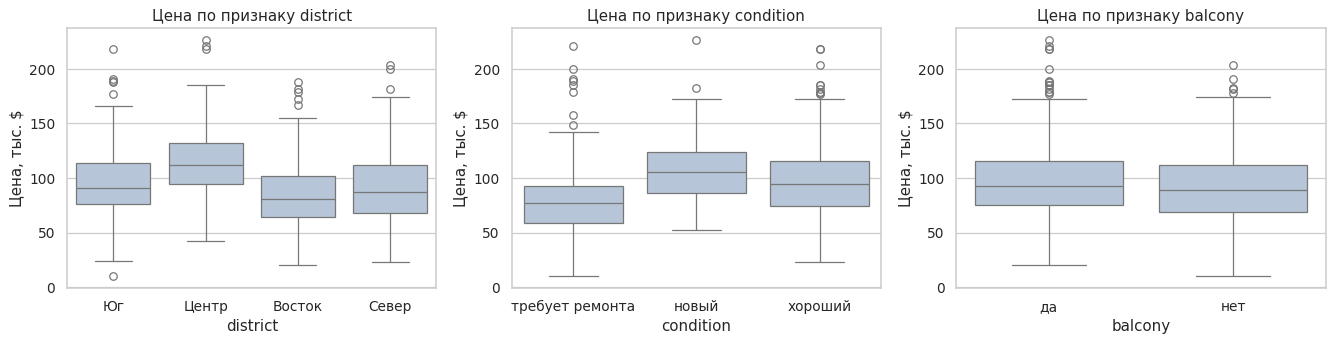

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["district", "condition", "balcony"]):
    sns.boxplot(data=clean, x=col, y="price_kusd", ax=ax, color="lightsteelblue")
    ax.set_title(f"Цена по признаку {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Цена, тыс. $")
plt.tight_layout()
plt.show()
print(clean.groupby("district")["price_kusd"].mean().round(1).sort_values())

**Что видно:** категориальные признаки влияют на цену: в «Центре» квартиры в среднем дороже (≈115 тыс. $) всего остального (≈84–95), у квартир «требует ремонта» цена ниже (≈80), чем у «новых» (≈106). Балкон даёт небольшую разницу (≈97 против ≈92).
## 6. Целевая переменная
Задача — **регрессия**, цена непрерывна, поэтому дисбаланс классов не оценивается (он применим только к классификации; им займёмся в ПР-5). Распределение цены смотрели выше: колоколообразное с небольшим правым хвостом, логарифмировать цель не обязательно.

## 7. Итоговый список проблем данных и план их устранения

| № | Проблема | Где обнаружена | Как устраним (ПР-3) |
|---|----------|----------------|---------------------|
| 1 | Пропуски в 6 признаках (condition ≈10%, year_built 8%, district 6%, dist_center_km 5%, area_m2 и floor по 3%) | `isnull()`, график пропусков | числовые — медианой (`SimpleImputer`), категориальные — отдельной категорией «неизвестно» |
| 2 | Ошибки ввода в `area_m2` (650–990 м²) | boxplot, гистограмма, корреляция 0,28 вместо 0,79 | правило `area_m2 > 400` → NaN, затем заполнение медианой |
| 3 | Невозможные годы постройки (1800, 1850, 2099) | boxplot `year_built`, IQR | год вне 1900–2026 → NaN, затем заполнение медианой |
| 4 | 10 полных дубликатов строк | `df.duplicated().sum()` | `drop_duplicates()` до разбиения на train/test |
| 5 | Мультиколлинеарность: `area_m2`, `area_sqft`, `living_area_m2` (r ≈ 0,98–1,0) | корреляционная матрица, scatter | оставим в пайплайне, проверим влияние на линейную модель в ПР-4 (VIF) |
| 6 | Разные масштабы признаков (площадь в футах до 1900, комнаты 1–6) | `describe()`, гистограммы | `StandardScaler` внутри пайплайна |

**Риск утечки данных:** все статистики для заполнения и масштабирования нужно вычислять только по обучающей выборке; правила очистки по «здравому смыслу» (пункты 2–4) статистику выборки не используют, поэтому их можно применять до разбиения.